In [1]:
import json, random, sys
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2

PROJECT_ROOT = Path.cwd().parent         
sys.path.insert(0, str(PROJECT_ROOT))

import utils.sunrgbd as sd

In [2]:
DATASET_ROOT = Path("/Users/polina_sushko/My_work/University/ВКР/SUNRGBD")
OUT_DIR      = Path("outputs")

TOP_K_CLASSES                     = 10 # how many most frequent categories to keep
VAL_FRACTION, TEST_FRACTION, SEED = 0.15, 0.15, 42 # subset fractions and RNG seed (for reproducibility)
MIN_MASK_AREA, MIN_BBOX_SIDE      = 200.0, 8.0 # small-object filters
REQUIRE_INTRINSICS                = True # keep only scenes with camera intrinsics (needed for 3D in chapter 3)

OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Dataset:", DATASET_ROOT)
print("Exists:", DATASET_ROOT.is_dir())

Dataset: /Users/polina_sushko/My_work/University/ВКР/SUNRGBD
Exists: True


---
## Dataset scan

In [3]:
scenes = sd.find_scenes(DATASET_ROOT, require_annotation = False)
print(f"Scenes found: {len(scenes)}")

# group frames for a leak-free train/val/test split
sd.assign_groups(scenes)
print(f"Unique scene groups: {len({s.group_key for s in scenes})}")

Scenes found: 10335
Unique scene groups: 7954


In [4]:
rows = []
for i, s in enumerate(scenes, 1):
    if i % 500 == 0 or i == len(scenes):
        print(f"  processed {i}/{len(scenes)}", end="\r")
    intr = sd.read_intrinsics(s.intrinsics_path)
    anns = sd.load_annotations(s.annotation_path)
    rows.append({
        "rel_key": s.rel_key, "group_key": s.group_key,
        "sensor": s.sensor, "collection": s.collection, "scene_type": s.scene_type,
        "has_intrinsics": intr is not None,
        "fx": intr.fx if intr else None, "fy": intr.fy if intr else None,
        "cx": intr.cx if intr else None, "cy": intr.cy if intr else None,
        "n_objects": len(anns),
        "depth_source": getattr(s, "depth_source", ""),
    })
print()

scan_df = pd.DataFrame(rows)
scan_df.to_csv(OUT_DIR / "scenes_index.csv", index=False)

usable = scan_df[(scan_df.n_objects > 0) & scan_df.has_intrinsics]
print(f"Total scenes:              {len(scan_df)}")
print(f"With object annotations:   {(scan_df.n_objects > 0).sum()}")
print(f"With camera intrinsics:    {scan_df.has_intrinsics.sum()}")
print(f"Usable:                    {len(usable)}")
print(f"Total annotated objects:   {scan_df.n_objects.sum()}")

display(scan_df.sensor.value_counts().to_frame("Scene count"))
scan_df.head()

  processed 10335/10335
Total scenes:              10335
With object annotations:   10295
With camera intrinsics:    10335
Usable:                    10295
Total annotated objects:   173502


,Scene count
sensor,
kv2,3784
xtion,3389
kv1,2003
realsense,1159


,rel_key,group_key,sensor,collection,scene_type,has_intrinsics,fx,fy,cx,cy,n_objects,depth_source
0,kv1/NYUdata/NYU0001,kv1/NYUdata/NYU0001,kv1,NYUdata,kitchen,True,518.857901,519.469611,284.582449,208.736166,26,depth_bfx
1,kv1/NYUdata/NYU0002,kv1/NYUdata/NYU0002,kv1,NYUdata,kitchen,True,518.857901,519.469611,284.582449,208.736166,28,depth_bfx
2,kv1/NYUdata/NYU0003,kv1/NYUdata/NYU0003,kv1,NYUdata,office,True,518.857901,519.469611,284.582449,208.736166,21,depth_bfx
3,kv1/NYUdata/NYU0004,kv1/NYUdata/NYU0004,kv1,NYUdata,office,True,518.857901,519.469611,284.582449,208.736166,24,depth_bfx
4,kv1/NYUdata/NYU0005,kv1/NYUdata/NYU0005,kv1,NYUdata,office,True,518.857901,519.469611,284.582449,208.736166,34,depth_bfx


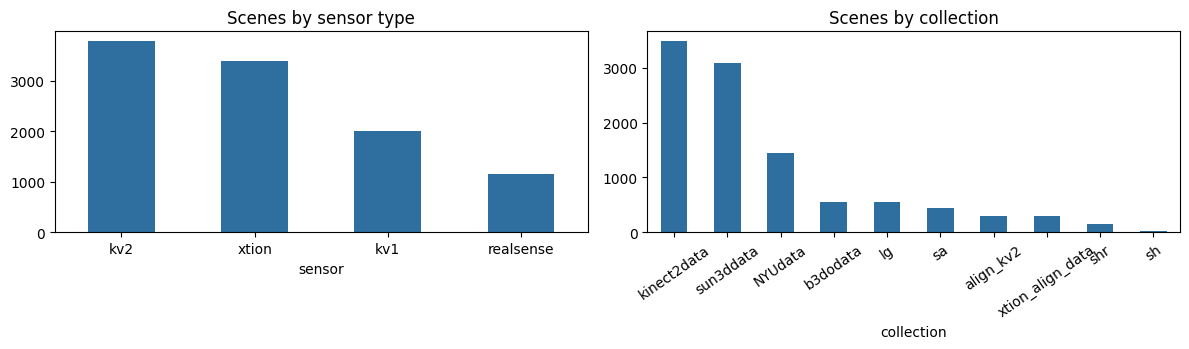

In [5]:
# scene distribution by sensor and collection
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
scan_df.sensor.value_counts().plot.bar(ax=axes[0], color="#2f6f9f")
axes[0].set_title("Scenes by sensor type"); axes[0].tick_params(axis="x", rotation=0)
scan_df.collection.value_counts().head(10).plot.bar(ax=axes[1], color="#2f6f9f")
axes[1].set_title("Scenes by collection"); axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

### Camera parameters

The dataset uses four sensor types, and their focal lengths are **different**.
This is why the camera parameters are read per scene rather than once.

fx                 fy                 cx                cy       \
            mean   std count   mean   std count   mean  std count   mean  std   
sensor                                                                          
kv1        519.3   0.7  2003  519.8   0.6  2003  282.7  3.0  2003  210.5  2.9   
kv2        529.5   0.0  3784  529.5   0.0  3784  365.0  0.0  3784  265.0  0.0   
realsense  693.7   0.3  1159  693.7   0.3  1159  360.5  0.3  1159  264.8  0.0   
xtion      567.0  10.7  3389  567.0  10.7  3389  308.3  5.4  3389  225.5  1.7   

                 
          count  
sensor           
kv1        2003  
kv2        3784  
realsense  1159  
xtion      3389

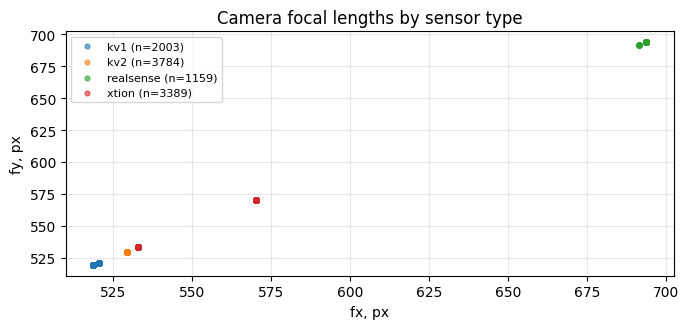

In [6]:
intr_df = scan_df[scan_df.has_intrinsics]
display(intr_df.groupby("sensor")[["fx", "fy", "cx", "cy"]].agg(["mean", "std", "count"]).round(1))

fig, ax = plt.subplots(figsize=(7, 3.4))
for sensor, grp in intr_df.groupby("sensor"):
    ax.scatter(grp.fx, grp.fy, s=12, alpha=0.6, label=f"{sensor} (n={len(grp)})")
ax.set_xlabel("fx, px"); ax.set_ylabel("fy, px")
ax.set_title("Camera focal lengths by sensor type")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
## Building the COCO annotations

We convert the annotations from `annotation2Dfinal/index.json` into the standard COCO format.

Filtering applied:
* **"stuff"** categories (wall, floor, ceiling) are excluded — they are not object instances;
* degenerate polygons (fewer than three points) and overly small masks are dropped;
* **class names are normalized**: they were typed in by hand, so `chair`, `Chair `,
  `chair2`, `chairs` all occur. Without normalization one class splinters into dozens.

In [7]:
scenes_ann = [s for s in scenes if s.annotation_path is not None]
print(f"Scenes with annotation files: {len(scenes_ann)}")

images, annotations = [], []
category_ids, category_counts = {}, Counter()
raw_to_norm, skipped = {}, Counter()
ann_id = 1

for img_id, scene in enumerate(scenes_ann, start=1):
    if img_id % 250 == 0 or img_id == len(scenes_ann):
        print(f"  processed {img_id}/{len(scenes_ann)}", end="\r")

    intr = sd.read_intrinsics(scene.intrinsics_path)
    if REQUIRE_INTRINSICS and intr is None:
        skipped["scene without camera intrinsics"] += 1
        continue
    try:
        with Image.open(scene.rgb_path) as im:
            width, height = im.size
    except OSError:
        skipped["unreadable RGB"] += 1
        continue

    anns = sd.load_annotations(scene.annotation_path)
    if not anns:
        skipped["empty annotations"] += 1
        continue

    kept = 0
    for obj in anns:
        raw_to_norm.setdefault(obj.raw_name.strip().lower(), obj.name)
        if not obj.name or obj.name in sd.STUFF_CLASSES:
            skipped["stuff category"] += 1
            continue

        polys = [sd.clip_polygon(p, width, height) for p in obj.polygons]
        polys = [p for p in polys if len(p) >= 6]
        if not polys:
            skipped["degenerate polygon"] += 1
            continue

        bbox, area = sd.polygons_bbox_area(polys, width, height)
        if area < MIN_MASK_AREA:
            skipped["mask area too small"] += 1
            continue
        if bbox[2] < MIN_BBOX_SIDE or bbox[3] < MIN_BBOX_SIDE:
            skipped["bounding box too small"] += 1
            continue

        category_ids.setdefault(obj.name, len(category_ids) + 1)
        category_counts[obj.name] += 1
        annotations.append({
            "id": ann_id, "image_id": img_id,
            "category_id": category_ids[obj.name],
            "segmentation": [[round(v, 2) for v in p] for p in polys],
            "bbox": [round(v, 2) for v in bbox], "area": round(area, 2),
            "iscrowd": 0,
        })
        ann_id += 1; kept += 1

    if kept == 0:
        skipped["scene with no usable objects"] += 1
        continue

    # paths are stored RELATIVE to the dataset root — so the COCO files
    # work on any machine (Colab, Kaggle), not just locally
    images.append({
        "id": img_id, "file_name": scene.rgb_path.relative_to(DATASET_ROOT).as_posix(),
        "width": width, "height": height,
        # fields needed for 3D reconstruction
        "depth_file": scene.depth_path.relative_to(DATASET_ROOT).as_posix(),
        "depth_source": getattr(scene, "depth_source", ""),
        "sensor": scene.sensor, "collection": scene.collection,
        "scene_type": scene.scene_type, "rel_key": scene.rel_key,
        "group_key": scene.group_key,
        "fx": intr.fx if intr else None, "fy": intr.fy if intr else None,
        "cx": intr.cx if intr else None, "cy": intr.cy if intr else None,
    })
print()
print(f"Images: {len(images)}   Instances: {len(annotations)}   Categories: {len(category_ids)}")

Scenes with annotation files: 10335
  processed 10335/10335
Images: 10294   Instances: 125386   Categories: 9343


In [15]:
# save the COCO file
valid_ids = {a["image_id"] for a in annotations}
images = [im for im in images if im["id"] in valid_ids]

coco = {
    "info": {"description": "SUN RGB-D instance segmentation (from annotation2Dfinal)",
             "version": "1.0", "source_root": str(DATASET_ROOT)},
    "licenses": [], "images": images, "annotations": annotations,
    "categories": [{"id": cid, "name": n, "supercategory": "object"}
                   for n, cid in sorted(category_ids.items(), key=lambda kv: kv[1])],
}
coco_path = OUT_DIR / "sunrgbd_instances_all.json"
coco_path.write_text(json.dumps(coco), encoding="utf-8")
print(f"Saved: {coco_path}")

if skipped:
    print("\nFiltered out:")
    for reason, cnt in skipped.most_common():
        print(f"   {reason:<35} {cnt}")

# name-normalization map — useful for the thesis text
norm_df = pd.DataFrame(sorted(raw_to_norm.items()), columns=["Raw name", "Normalized"])
norm_df.to_csv(OUT_DIR / "name_normalization_map.csv", index=False)
changed = norm_df[norm_df["Raw name"] != norm_df["Normalized"]]
print(f"\nNames normalized: {len(changed)} of {len(norm_df)}")
display(changed.head(15))

Збережено: outputs/sunrgbd_instances_all.json

Відфільтровано:
   категорія stuff                     32714
   замала площа маски                  13350
   замала обмежувальна рамка           834
   порожні анотації                    40
   сцена без придатних об'єктів        1

Назв нормалізовано: 1449 з 11224


,Вихідна назва,Нормалізована
24,2x4,2x
64,able2,able
89,acvent2,acvent
121,air_conditioner,air conditioner
122,air_conditioner_sistem,air conditioner sistem
123,air_vent,air vent
160,airventsonfloorsection1,airventsonfloorsection
161,airventsonfloorsection2,airventsonfloorsection
162,airventsonfloorsection3,airventsonfloorsection
207,announcementboard1,announcementboard


In [18]:
# check: can the COCO file be read by the standard evaluation tooling
from pycocotools.coco import COCO
_c = COCO(str(coco_path))
_img = _c.getImgIds()[0]
_ann = _c.loadAnns(_c.getAnnIds(imgIds=_img))[0]
_mask = _c.annToMask(_ann)
print(f"pycocotools: file is valid. Example mask {_mask.shape}, "
      f"area {_mask.sum()} (area field = {_ann['area']:.0f})")

loading annotations into memory...
Done (t=0.55s)
creating index...
index created!
pycocotools: файл коректний. Приклад маски (427, 561), площа 487 (поле area = 539)


---
## Visual inspection and 3D-projection sanity check

For each scene a panel is built:

1. the original RGB image
2. RGB with instance masks overlaid
3. the decoded depth map (in meters)
4. a trial back-projection into 3D

### Why the depth must be decoded

In SUN RGB-D the depth map is stored **with a bit shift**: the three lowest bits
are moved to the top. Without the inverse shift the map looks like random noise.
Equivalent of the original MATLAB code:

```matlab
depth = bitor(bitshift(d, -3), bitshift(d, 13));
```

Implemented in `sunrgbd.decode_depth()`.

**The fourth panel is a camera-parameter sanity check.** If the depth is decoded
incorrectly or the `intrinsics` are read wrongly, the point cloud will have
distorted geometry: planes become curved and proportions implausible.

In [ ]:
# demonstration: what the bit shift does
_demo = next(im for im in images if (DATASET_ROOT / im["depth_file"]).is_file())
_raw = np.array(Image.open(DATASET_ROOT / _demo["depth_file"]))
if _raw.ndim == 3:
    _raw = _raw[..., 0]
_wrong = _raw.astype(np.float32) / 1000.0          # without the shift (wrong)
_right = sd.decode_depth(_raw)                     # with the shift (correct)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, data, title in (
    (axes[0], _wrong, "WITHOUT the bit shift (wrong)"),
    (axes[1], _right, "With the bit shift (correct)"),
):
    m = np.ma.masked_where(data <= 0, data)
    im_ = ax.imshow(m, cmap="viridis")
    valid = data[data > 0]
    med = np.median(valid) if valid.size else 0
    ax.set_title(f"{title}\nmedian {med:.2f} m", fontsize=9)
    ax.axis("off")
    fig.colorbar(im_, ax=ax, fraction=0.045)
plt.tight_layout(); plt.show()

print("Rule of thumb: for an indoor scene the median depth should be about 1.5-4 m.")

In [ ]:
PALETTE = np.array([
    [230,25,75],[60,180,75],[255,225,25],[0,130,200],[245,130,48],[145,30,180],
    [70,240,240],[240,50,230],[210,245,60],[250,190,190],[0,128,128],[230,190,255],
    [170,110,40],[255,250,200],[128,0,0],[170,255,195],[128,128,0],[255,215,180],
], dtype=np.uint8)

cats_by_id = {c_["id"]: c_["name"] for c_ in coco["categories"]}
anns_by_img = defaultdict(list)
for a in annotations:
    anns_by_img[a["image_id"]].append(a)


def overlay_masks(rgb, masks, alpha=0.5):
    out = rgb.astype(np.float32).copy()
    for i, m in enumerate(masks):
        sel = m.astype(bool)
        out[sel] = (1 - alpha) * out[sel] + alpha * PALETTE[i % len(PALETTE)]
    return out.astype(np.uint8)


def inspect_scene(img_info, max_points=8000):
    """Builds an overview panel for one scene and returns sanity metrics."""

    rgb = sd.read_rgb(DATASET_ROOT / img_info["file_name"])
    depth = sd.read_depth(DATASET_ROOT / img_info["depth_file"])
    h, w = rgb.shape[:2]
    if depth.shape[:2] != (h, w):
        depth = cv2.resize(depth, (w, h), interpolation=cv2.INTER_NEAREST)

    masks, labels = [], []
    for a in anns_by_img.get(img_info["id"], []):
        m = sd.polygons_to_mask(a["segmentation"], w, h)
        if m.any():
            masks.append(m); labels.append(cats_by_id[a["category_id"]])

    valid = depth > 0
    med = float(np.median(depth[valid])) if valid.any() else 0.0

    fig = plt.figure(figsize=(17, 4.3))
    ax1 = fig.add_subplot(1, 4, 1); ax1.imshow(rgb)
    ax1.set_title(f"RGB ({w}×{h}), {img_info['sensor']}", fontsize=9); ax1.axis("off")

    ax2 = fig.add_subplot(1, 4, 2); ax2.imshow(overlay_masks(rgb, masks))
    ax2.set_title(f"Masks: {len(masks)}\n{', '.join(sorted(set(labels))[:5])}", fontsize=8)
    ax2.axis("off")

    ax3 = fig.add_subplot(1, 4, 3)
    im_ = ax3.imshow(np.ma.masked_where(depth <= 0, depth), cmap="viridis")
    ax3.set_title(f"Depth: median {med:.2f} m\nvalid {valid.mean():.0%}", fontsize=8)
    ax3.axis("off"); fig.colorbar(im_, ax=ax3, fraction=0.045)

    ax4 = fig.add_subplot(1, 4, 4, projection="3d")
    if img_info.get("fx"):
        intr = sd.Intrinsics(img_info["fx"], img_info["fy"], img_info["cx"], img_info["cy"])
        stride = max(1, int(np.sqrt(max(valid.sum(), 1) / max_points)))
        pts, cols = sd.backproject(depth, intr, rgb=rgb, stride=stride)
        if len(pts):
            ax4.scatter(pts[:,0], pts[:,2], -pts[:,1], c=cols, s=1.0, marker=".", linewidths=0)
            ax4.set_xlabel("X, m", fontsize=7); ax4.set_ylabel("Z, m", fontsize=7)
            ax4.set_zlabel("−Y, m", fontsize=7)
            ax4.view_init(elev=12, azim=-72); ax4.tick_params(labelsize=6)
            ax4.set_title("3D-projection check", fontsize=9)
    else:
        ax4.set_title("No camera intrinsics", fontsize=9)

    fig.suptitle(img_info["rel_key"], fontsize=9)
    plt.tight_layout(); plt.show()

    return {"rel_key": img_info["rel_key"], "sensor": img_info["sensor"],
            "n_objects": len(masks), "depth_valid_ratio": round(float(valid.mean()), 3),
            "depth_median_m": round(med, 2)}

In [ ]:
# inspect a random sample of scenes (the RNG is seeded — panels are reproducible)
N_CHECK = 5
sample = random.Random(SEED).sample(images, min(N_CHECK, len(images)))
check_rows = [inspect_scene(im) for im in sample]

check_df = pd.DataFrame(check_rows)
display(check_df)
print(f"Median depth over the sample: {check_df.depth_median_m.median():.2f} m")

### A single object in 3D

Let's verify the key operation: back-projecting an **individual mask** into 3D
space. This is exactly how point clouds will be formed for every segmented
object.

In [ ]:
# take a scene with enough objects
demo = next((im for im in sample if len(anns_by_img.get(im["id"], [])) >= 2 and im.get("fx")), None)

rgb = sd.read_rgb(DATASET_ROOT / demo["file_name"])
depth = sd.read_depth(DATASET_ROOT / demo["depth_file"])
h, w = rgb.shape[:2]
if depth.shape[:2] != (h, w):
    depth = cv2.resize(depth, (w, h), interpolation=cv2.INTER_NEAREST)
intr = sd.Intrinsics(demo["fx"], demo["fy"], demo["cx"], demo["cy"])

fig = plt.figure(figsize=(13, 4.6))
ax = fig.add_subplot(1, 2, 1, projection="3d")
stats = []
for i, a in enumerate(anns_by_img[demo["id"]][:6]):
    mask = sd.polygons_to_mask(a["segmentation"], w, h)
    pts, _ = sd.backproject(depth, intr, mask=mask, stride=2)
    if len(pts) < 30:
        continue
    color = PALETTE[i % len(PALETTE)] / 255.0
    ax.scatter(pts[:,0], pts[:,2], -pts[:,1], s=2, color=color,
               label=cats_by_id[a["category_id"]], marker=".", linewidths=0)
    size = pts.max(0) - pts.min(0)
    stats.append({
        "Class": cats_by_id[a["category_id"]], "Points": len(pts),
        "Distance, m": round(float(np.median(pts[:,2])), 2),
        "Width, m": round(float(size[0]), 2),
        "Height, m": round(float(size[1]), 2),
        "Depth, m": round(float(size[2]), 2),
    })
ax.set_xlabel("X, m", fontsize=8); ax.set_ylabel("Z, m", fontsize=8)
ax.set_zlabel("−Y, m", fontsize=8)
ax.set_title("Objects as separate point clouds", fontsize=9)
ax.legend(fontsize=7, loc="upper left"); ax.view_init(elev=14, azim=-70)
ax.tick_params(labelsize=6)

ax2 = fig.add_subplot(1, 2, 2); ax2.imshow(rgb); ax2.axis("off")
ax2.set_title("Source scene", fontsize=9)
plt.tight_layout(); plt.show()

display(pd.DataFrame(stats))

---
## Exploratory data analysis (EDA)

In [27]:
anns_df = pd.DataFrame([{
    "image_id": a["image_id"], "category": cats_by_id[a["category_id"]], "area": a["area"],
    "bbox_w": a["bbox"][2], "bbox_h": a["bbox"][3],
} for a in annotations])
imgs_df = pd.DataFrame(images)

per_cat = (anns_df.groupby("category")
           .agg(n_instances=("area", "size"), n_images=("image_id", "nunique"),
                median_area=("area", "median"))
           .sort_values("n_instances", ascending=False))
per_cat["share_%"] = (per_cat.n_instances / len(anns_df) * 100).round(2)
per_cat.to_csv(OUT_DIR / "class_distribution.csv")

print(f"Images: {len(imgs_df)}   Instances: {len(anns_df)}   Categories: {len(per_cat)}")
display(per_cat.head(20))

Зображень: 10294   Екземплярів: 126604   Категорій: 9466


,n_instances,n_images,median_area,share_%
category,,,,
chair,17274,5687,6743.0,13.64
table,9484,5612,13989.5,7.49
window,4015,2684,10673.0,3.17
book,3257,1330,1532.0,2.57
picture,3048,1383,1983.0,2.41
door,2975,2363,11149.0,2.35
pillow,2784,1221,3476.0,2.20
cabinet,2351,1358,11303.0,1.86
paper,2324,1427,1692.5,1.84


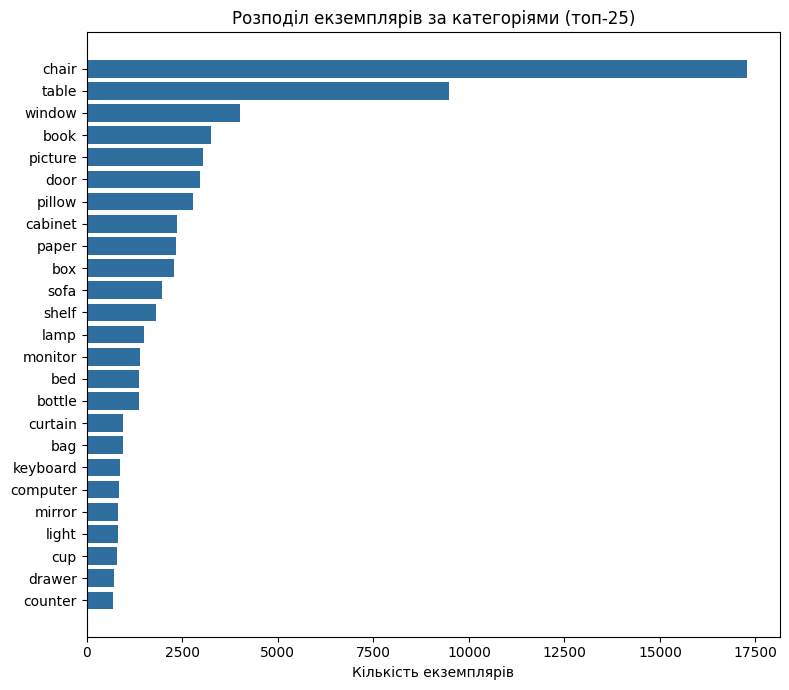

In [ ]:
# instance distribution over categories
top = per_cat.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, max(4, 0.28 * len(top))))
ax.barh(top.index, top.n_instances, color="#2f6f9f")
ax.set_xlabel("Number of instances")
ax.set_title("Instance distribution over categories (top 25)")
plt.tight_layout(); plt.savefig(OUT_DIR / "class_distribution.png", bbox_inches="tight"); plt.show()

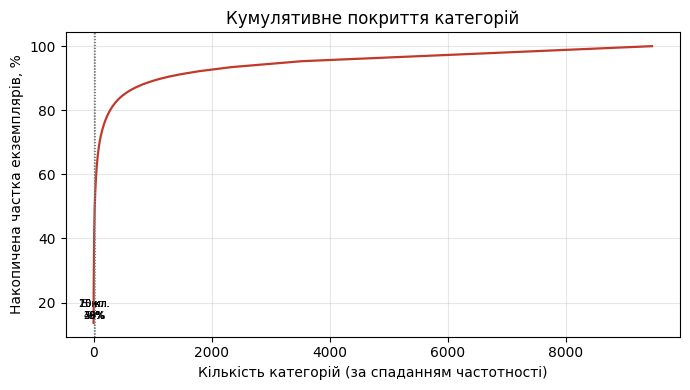

Топ-10 категорій покривають 39.3% усіх екземплярів.


In [32]:
# cumulative coverage — rationale for choosing the top-K classes (step 1.6)
cum = per_cat.n_instances.cumsum() / per_cat.n_instances.sum() * 100
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(cum) + 1), cum.values, color="#c0392b", lw=1.6)
for k in (5, 10, 15, 20):
    if k <= len(cum):
        ax.axvline(k, ls=":", lw=0.8, color="grey")
        ax.text(k, 15, f"{k} cls\n{cum.values[k-1]:.0f}%", fontsize=7, ha="center")
ax.set_xlabel("Number of categories (by descending frequency)")
ax.set_ylabel("Cumulative share of instances, %")
ax.set_title("Cumulative category coverage"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "class_cumulative_coverage.png", bbox_inches="tight"); plt.show()

print(f"The top {TOP_K_CLASSES} categories cover "
      f"{cum.values[min(TOP_K_CLASSES, len(cum)) - 1]:.1f}% of all instances.")

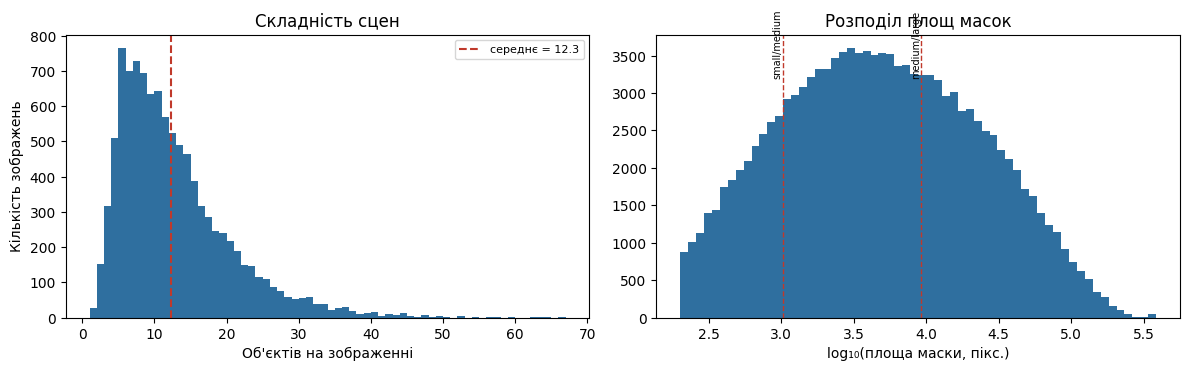

Градації розміру за критерієм COCO:


,n_instances,share_%
area,,
small,23395,18.5
medium,58481,46.2
large,44728,35.3


In [ ]:
# objects per image and mask-area distribution
per_img = anns_df.groupby("image_id").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(per_img.values, bins=range(1, int(per_img.max()) + 2), color="#2f6f9f")
axes[0].axvline(per_img.mean(), color="#c0392b", ls="--", label=f"mean = {per_img.mean():.1f}")
axes[0].set_xlabel("Objects per image"); axes[0].set_ylabel("Number of images")
axes[0].set_title("Scene complexity"); axes[0].legend(fontsize=8)

axes[1].hist(np.log10(np.clip(anns_df.area.values, 1, None)), bins=60, color="#2f6f9f")
for thr, lbl in ((32**2, "small/medium"), (96**2, "medium/large")):
    axes[1].axvline(np.log10(thr), color="#c0392b", ls="--", lw=1)
    axes[1].text(np.log10(thr), axes[1].get_ylim()[1]*0.85, lbl, fontsize=7, rotation=90, ha="right")
axes[1].set_xlabel("log₁₀(mask area, px)"); axes[1].set_title("Mask area distribution")
plt.tight_layout(); plt.savefig(OUT_DIR / "objects_and_areas.png", bbox_inches="tight"); plt.show()

size_bins = pd.cut(anns_df.area, [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"])
size_tbl = size_bins.value_counts().sort_index().to_frame("n_instances")
size_tbl["share_%"] = (size_tbl.n_instances / len(anns_df) * 100).round(1)
size_tbl.to_csv(OUT_DIR / "size_distribution.csv")
print("Size grades per the COCO criterion:"); display(size_tbl)

In [ ]:
# depth-map quality on a subsample (seeded — reproducible)
DEPTH_SAMPLE = 200
sample_imgs = random.Random(SEED).sample(images, min(DEPTH_SAMPLE, len(images)))
rows = []
for i, im in enumerate(sample_imgs, 1):
    if i % 50 == 0:
        print(f"  {i}/{len(sample_imgs)}", end="\r")
    p = DATASET_ROOT / im["depth_file"]
    if not p.is_file():
        continue
    d = sd.read_depth(p); v = d > 0
    rows.append({"sensor": im["sensor"], "valid_ratio": float(v.mean()),
                 "median_m": float(np.median(d[v])) if v.any() else np.nan})
print()

depth_df = pd.DataFrame(rows)
depth_df.to_csv(OUT_DIR / "depth_stats_sample.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(depth_df.valid_ratio.dropna(), bins=30, color="#2f6f9f")
axes[0].set_xlabel("Share of valid pixels"); axes[0].set_ylabel("Images")
axes[0].set_title("Depth-map completeness")
axes[1].hist(depth_df.median_m.dropna(), bins=30, color="#2f6f9f")
axes[1].set_xlabel("Median scene depth, m"); axes[1].set_title("Scene depth distribution")
plt.tight_layout(); plt.savefig(OUT_DIR / "depth_quality.png", bbox_inches="tight"); plt.show()

display(depth_df.groupby("sensor")[["valid_ratio", "median_m"]].agg(["mean", "count"]).round(3))

---
## Target category selection

We use the **standard 10-class SUN RGB-D list** (*bed, chair, sofa, table, desk,
toilet, dresser, nightstand, bookshelf, bathtub*) — the same one used by most
detection and segmentation publications on this dataset. This gives:

* **comparability** of results with published work;
* classes with a clear 3D shape — computing dimensions and volume for them
  (chapter 3) is physically meaningful, unlike flat categories
  (paper, picture, window);
* enough examples per class for training.

The alternative — the top-K most frequent classes — remains available via
`TOP_K_CLASSES` (to use it, set `MANUAL_CLASSES = []`).

In [ ]:
# the standard 10-class SUN RGB-D list (defined in utils/sunrgbd.py);
# to fall back to top-K by frequency, set MANUAL_CLASSES = []
MANUAL_CLASSES = list(sd.STANDARD_10_CLASSES)

keep_names = MANUAL_CLASSES or list(per_cat.head(TOP_K_CLASSES).index)
missing = [n for n in keep_names if n not in per_cat.index]
if missing:
    raise ValueError(f"Classes not present in the data: {missing}")

coverage = per_cat.loc[keep_names, "n_instances"].sum() / len(anns_df) * 100
print(f"Categories selected: {len(keep_names)}")
print(f"They cover {coverage:.1f}% of all annotated instances\n")
display(per_cat.loc[keep_names, ["n_instances", "n_images", "share_%"]])

In [34]:
# renumber categories from 1 (a COCO / Detectron2 requirement)
new_cats = [{"id": i, "name": n, "supercategory": "object"} for i, n in enumerate(keep_names, 1)]
name2new = {c_["name"]: c_["id"] for c_ in new_cats}

kept_anns = []
for a in annotations:
    name = cats_by_id[a["category_id"]]
    if name in name2new:
        b = dict(a); b["category_id"] = name2new[name]
        kept_anns.append(b)

MIN_OBJECTS_PER_IMAGE = 1
counts_per_img = Counter(a["image_id"] for a in kept_anns)
keep_ids = {i for i, n in counts_per_img.items() if n >= MIN_OBJECTS_PER_IMAGE}
kept_imgs = [im for im in images if im["id"] in keep_ids]
kept_anns = [a for a in kept_anns if a["image_id"] in keep_ids]

print(f"After filtering: {len(kept_imgs)} images, {len(kept_anns)} instances")

Після фільтрації: 9432 зображень, 49806 екземплярів


---
## Train / validation / test split

Two key points:

**The split is done over scene groups, not individual frames.** In the
`sun3ddata` collection many frames were captured in the same room back to back.
If such frames land in both the training and the test set, the quality estimate
becomes **inflated** — the model effectively sees the test scenes during training.

**The split is deterministic.** The RNG seed is fixed and the result is saved to
a file. Splitting randomly on every run is not acceptable: metrics of different
experiments would become incomparable.

In [35]:
groups = defaultdict(list)
for im in kept_imgs:
    groups[im.get("group_key") or im["rel_key"]].append(im)

group_keys = sorted(groups)
rng = random.Random(SEED)
shuffled = list(group_keys); rng.shuffle(shuffled)

n = len(shuffled)
n_test, n_val = int(round(n * TEST_FRACTION)), int(round(n * VAL_FRACTION))
assign = {}
for i, g in enumerate(shuffled):
    assign[g] = "test" if i < n_test else ("val" if i < n_test + n_val else "train")

split_images = {"train": [], "val": [], "test": []}
for g, subset in assign.items():
    split_images[subset].extend(groups[g])

print(f"Scene groups: {len(group_keys)}  →  "
      f"train {sum(1 for v in assign.values() if v=='train')}, "
      f"val {sum(1 for v in assign.values() if v=='val')}, "
      f"test {sum(1 for v in assign.values() if v=='test')}")

Груп сцен: 7350  →  train 5146, val 1102, test 1102


In [36]:
SPLIT_DIR = OUT_DIR / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

summary, dist_rows = [], []
for subset, imgs in split_images.items():
    ids = {im["id"] for im in imgs}
    sub_anns = [a for a in kept_anns if a["image_id"] in ids]
    out = {"info": {**coco.get("info", {}), "subset": subset}, "licenses": [],
           "images": imgs, "annotations": sub_anns, "categories": new_cats}
    (SPLIT_DIR / f"instances_{subset}.json").write_text(json.dumps(out), encoding="utf-8")

    summary.append({"Subset": subset, "Images": len(imgs), "Instances": len(sub_anns),
                    "Share, %": round(len(imgs) / len(kept_imgs) * 100, 1)})
    cc = Counter(a["category_id"] for a in sub_anns)
    for c_ in new_cats:
        dist_rows.append({"subset": subset, "category": c_["name"],
                          "n_instances": cc.get(c_["id"], 0)})

display(pd.DataFrame(summary))

dist = (pd.DataFrame(dist_rows).pivot(index="category", columns="subset", values="n_instances")
        .fillna(0).astype(int))
dist = dist[[c_ for c_ in ("train", "val", "test") if c_ in dist.columns]]
dist["total"] = dist.sum(axis=1)
dist = dist.sort_values("total", ascending=False)
dist.to_csv(SPLIT_DIR / "split_class_distribution.csv")
print("\nInstance distribution over classes:"); display(dist)

,Вибірка,Зображень,Екземплярів,"Частка, %"
0,train,6482,34362,68.7
1,val,1402,7387,14.9
2,test,1548,8057,16.4



Розподіл екземплярів за класами:


subset,train,val,test,total
category,,,,
chair,11991,2502,2781,17274
table,6597,1412,1475,9484
window,2808,612,595,4015
book,2116,549,592,3257
picture,2089,429,530,3048
door,2039,429,507,2975
pillow,1839,448,497,2784
cabinet,1670,333,348,2351
paper,1608,344,372,2324


In [37]:
# check: no leak between the subsets
seen, leaks = {}, set()
for subset, imgs in split_images.items():
    for im in imgs:
        g = im.get("group_key", "")
        if g in seen and seen[g] != subset:
            leaks.add(g)
        seen[g] = subset

if leaks:
    print(f"WARNING: {len(leaks)} groups ended up in different subsets!")
else:
    print("No leak: every scene group belongs to exactly one subset.")

# freeze the split to a file — so it can be reproduced
pd.DataFrame([
    {"rel_key": im["rel_key"], "image_id": im["id"], "group_key": im.get("group_key", ""),
     "subset": subset, "sensor": im["sensor"]}
    for subset, imgs in split_images.items() for im in imgs
]).sort_values(["subset", "rel_key"]).to_csv(SPLIT_DIR / "split_assignment.csv", index=False)
print(f"Split saved: {SPLIT_DIR / 'split_assignment.csv'}")

Витоку немає: кожна група сцен належить лише одній вибірці.
Поділ збережено: outputs/splits/split_assignment.csv


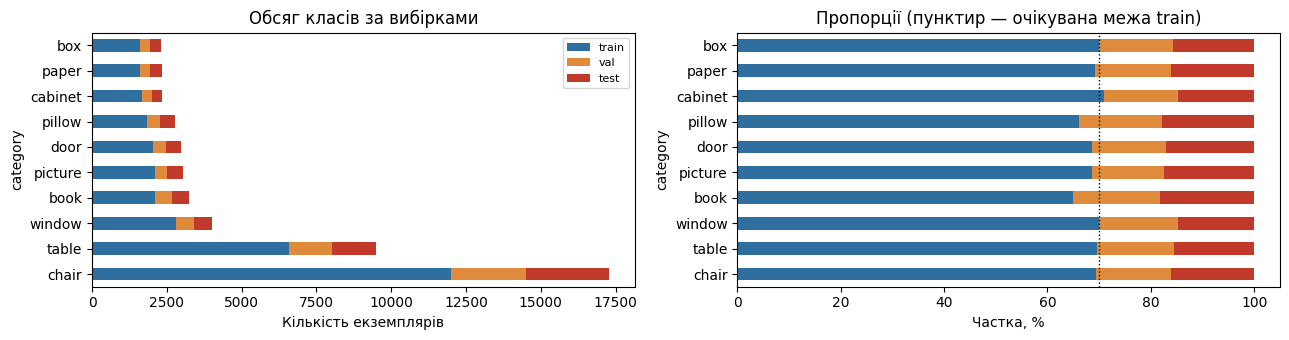

In [ ]:
# visual check of subset balance
share = dist[[c_ for c_ in ("train","val","test") if c_ in dist.columns]]
share = share.div(share.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, max(3.5, 0.32*len(dist))))
dist[[c_ for c_ in ("train","val","test") if c_ in dist.columns]].plot.barh(
    stacked=True, ax=axes[0], color=["#2f6f9f", "#e08b3c", "#c0392b"])
axes[0].set_xlabel("Number of instances"); axes[0].set_title("Class volumes per subset")
axes[0].legend(fontsize=8)

share.plot.barh(stacked=True, ax=axes[1], color=["#2f6f9f", "#e08b3c", "#c0392b"], legend=False)
axes[1].axvline(100*(1-VAL_FRACTION-TEST_FRACTION), color="k", ls=":", lw=1)
axes[1].set_xlabel("Share, %"); axes[1].set_title("Proportions (dotted line - expected train boundary)")
plt.tight_layout(); plt.savefig(OUT_DIR / "split_balance.png", bbox_inches="tight"); plt.show()

---
## Summary

Files prepared for model training:

* `outputs/splits/instances_train.json`
* `outputs/splits/instances_val.json`
* `outputs/splits/instances_test.json`

Every image also carries the `depth_file`, `fx`, `fy`, `cx`, `cy` fields —
they will be needed for building point clouds.

### Materials

| File | Purpose |
|---|---|
| `class_distribution.png` | instance distribution over categories |
| `class_cumulative_coverage.png` | rationale for the target-class choice |
| `objects_and_areas.png` | scene complexity and mask-area distribution |
| `depth_quality.png` | depth-map reliability |
| `split_balance.png` | subset balance |
| `splits/split_class_distribution.csv` | subset volume table |
| `name_normalization_map.csv` | category-name normalization |